### Cálculos de Score

In [49]:
import json
from pathlib import Path

LOG_DIR = Path("../Logs")

with (LOG_DIR / "indicadores_chat.json").open("r", encoding="utf-8") as file:
    indicadores_chat = json.load(file)

with (LOG_DIR / "indicadores_profissional.json").open("r", encoding="utf-8") as file:
    indicadores_profissional = json.load(file)

period_file = LOG_DIR / "indicadores_profissional_periodos.json"
if period_file.exists():
    with period_file.open("r", encoding="utf-8") as file:
        indicadores_profissional_periodos = json.load(file)
else:
    indicadores_profissional_periodos = {}


In [50]:
from __future__ import annotations

from dataclasses import asdict, dataclass
from typing import Any


@dataclass
class ScoreResult:
    userId: str
    date: str
    score: float | None
    components: dict[str, float | None]
    evidenceCoverage: float
    warnings: list[str]

    def to_dict(self) -> dict[str, Any]:
        return asdict(self)


# ======================================================================================
# Helpers
# ======================================================================================

def clamp(value: float, min_value: float = 0.0, max_value: float = 100.0) -> float:
    return max(min_value, min(value, max_value))


def round_score(value: float | None, digits: int = 2) -> float | None:
    return None if value is None else round(value, digits)


def safe_div(numerator: float, denominator: float, default: float | None = None) -> float | None:
    if denominator == 0:
        return default
    return numerator / denominator


def linear_score(
    value: float | None,
    min_value: float,
    max_value: float,
    invert: bool = False,
) -> float | None:
    if value is None or max_value == min_value:
        return None

    normalized = clamp((value - min_value) / (max_value - min_value), 0.0, 1.0)
    if invert:
        normalized = 1.0 - normalized
    return clamp(normalized * 100.0)


def weighted_score(
    components: dict[str, tuple[float | None, float]],
) -> tuple[float | None, float]:
    """
    Média ponderada apenas entre componentes efetivamente calculáveis.

    O segundo retorno representa a cobertura estrutural dos componentes disponíveis,
    não confiança estatística.
    """
    total_expected_weight = sum(weight for _, weight in components.values())
    available_weight = sum(
        weight
        for value, weight in components.values()
        if value is not None
    )

    if total_expected_weight <= 0 or available_weight <= 0:
        return None, 0.0

    score = sum(
        value * (weight / available_weight)
        for value, weight in components.values()
        if value is not None
    )
    coverage = available_weight / total_expected_weight
    return clamp(score), clamp(coverage, 0.0, 1.0)


def weighted_score_with_evidence(
    components: dict[str, tuple[float | None, float, float]],
) -> tuple[float | None, float]:
    """
    Calcula o score com os pesos definidos e mede a evidência separadamente.

    Diferentemente da versão anterior, menor evidência não altera silenciosamente o peso
    de um componente que já pôde ser calculado. Ela reduz somente evidenceCoverage.
    """
    score, _ = weighted_score({
        name: (value, weight)
        for name, (value, weight, _) in components.items()
    })

    total_expected_weight = sum(
        weight
        for _, weight, _ in components.values()
    )

    if total_expected_weight <= 0:
        return score, 0.0

    evidence_weight = sum(
        weight * clamp(evidence, 0.0, 1.0)
        for value, weight, evidence in components.values()
        if value is not None
    )

    return score, clamp(evidence_weight / total_expected_weight, 0.0, 1.0)


def baseline_pattern_score(
    value: float | None,
    reference: dict[str, Any] | None,
    minimum_scale: float,
) -> float | None:
    """
    Converte o desvio em relação ao baseline individual em 0..100.

    Usa mediana + MAD como referência robusta. O score chega a zero quando o desvio
    alcança aproximadamente três escalas robustas. `minimum_scale` evita explosão do
    desvio quando o baseline é praticamente constante.
    """
    if value is None or not reference:
        return None

    center = reference.get("median")
    mad = reference.get("mad")

    if not isinstance(center, (int, float)):
        return None

    robust_scale = (
        1.4826 * float(mad)
        if isinstance(mad, (int, float))
        else 0.0
    )
    fallback_scale = max(
        minimum_scale,
        abs(float(center)) * 0.20,
    )
    scale = max(robust_scale, fallback_scale)

    distance = abs(float(value) - float(center)) / scale
    return clamp((1.0 - min(distance / 3.0, 1.0)) * 100.0)


def baseline_value_pattern_score(
    value: float | None,
    baseline_value: float | None,
    minimum_scale: float,
) -> float | None:
    """Compara uma medida agregada do ciclo com o valor do próprio baseline."""
    if not isinstance(value, (int, float)) or not isinstance(baseline_value, (int, float)):
        return None

    fallback_scale = max(
        minimum_scale,
        abs(float(baseline_value)) * 0.20,
    )
    distance = abs(float(value) - float(baseline_value)) / fallback_scale
    return clamp((1.0 - min(distance / 3.0, 1.0)) * 100.0)


# ======================================================================================
# Chat Score
# ======================================================================================

def calculate_sentiment_score(
    sentiment_data: dict[str, Any],
) -> tuple[float | None, dict[str, float | None], float]:
    avg_positive = sentiment_data.get("avgPositiveScore")
    avg_negative = sentiment_data.get("avgNegativeScore")

    if avg_positive is None or avg_negative is None:
        return None, {
            "sentimentValenceScore": None,
            "negativeSafetyScore": None,
        }, 0.0

    # NEG já participa da valência. negativeSafetyScore permanece apenas diagnóstico.
    sentiment_valence_score = clamp(
        50.0 + 50.0 * (avg_positive - avg_negative)
    )
    negative_safety_score = clamp(
        100.0 * (1.0 - avg_negative)
    )

    return sentiment_valence_score, {
        "sentimentValenceScore": round_score(sentiment_valence_score),
        "negativeSafetyScore": round_score(negative_safety_score),
    }, 1.0


def calculate_linguistic_interaction_score(
    linguistic_data: dict[str, Any],
    lexical_period_data: dict[str, Any] | None = None,
) -> tuple[float | None, dict[str, float | None], float, list[str]]:
    """
    Mede estabilidade do padrão linguístico individual, não "qualidade da escrita".

    Tamanho e estrutura das mensagens continuam sendo observados diariamente contra o
    baseline individual. A diversidade lexical usa MATTR calculado no corpus agregado
    do ciclo; portanto, seu componente é constante entre os dias do mesmo período.
    """
    warnings: list[str] = []
    lexical_period_data = lexical_period_data or {}

    message_count = linguistic_data.get("messageCount")
    total_words = linguistic_data.get("totalWords")
    total_lemmas = linguistic_data.get("totalLemmas")
    avg_words_per_message = linguistic_data.get("avgWordsPerMessage")
    avg_sentences_per_message = linguistic_data.get("avgSentencesPerMessage")
    baseline_reference = linguistic_data.get("baselineReference", {})

    lexical_mattr = lexical_period_data.get("lexicalDiversityMattr")
    baseline_lexical_mattr = lexical_period_data.get("baselineLexicalDiversityMattr")
    lexical_sample_sufficient = lexical_period_data.get("sampleSufficient") is True

    message_evidence_score = None
    if message_count is not None:
        message_evidence_score = clamp((message_count / 2.0) * 100.0)

    message_length_pattern_score = baseline_pattern_score(
        avg_words_per_message,
        baseline_reference.get("avgWordsPerMessage"),
        minimum_scale=2.0,
    )
    sentence_pattern_score = baseline_pattern_score(
        avg_sentences_per_message,
        baseline_reference.get("avgSentencesPerMessage"),
        minimum_scale=0.25,
    )
    lexical_diversity_pattern_score = baseline_value_pattern_score(
        lexical_mattr,
        baseline_lexical_mattr,
        minimum_scale=0.08,
    )

    if lexical_diversity_pattern_score is None:
        window_size = lexical_period_data.get("mattrWindowSize")
        if lexical_period_data and not lexical_sample_sufficient:
            warnings.append(
                f"MATTR não utilizado porque o período possui menos de {window_size} lemas válidos."
            )
        else:
            warnings.append(
                "MATTR não utilizado porque não há diversidade lexical agregada do período ou referência do baseline."
            )

    linguistic_score, _ = weighted_score({
        "messageLengthPatternScore": (message_length_pattern_score, 0.35),
        "lexicalDiversityMattrPatternScore": (lexical_diversity_pattern_score, 0.45),
        "sentencePatternScore": (sentence_pattern_score, 0.20),
    })

    # O volume diário mede evidência para os padrões diários de tamanho/estrutura.
    # O componente lexical usa a suficiência do corpus do ciclo, não o volume daquele dia.
    daily_sample_coverage = 0.0
    if total_words is not None:
        daily_sample_coverage = min(total_words / 30.0, 1.0)
    elif total_lemmas is not None:
        daily_sample_coverage = min(total_lemmas / 15.0, 1.0)

    lexical_evidence = (
        1.0
        if lexical_diversity_pattern_score is not None and lexical_sample_sufficient
        else 0.0
    )

    evidence_coverage = (
        (0.35 * daily_sample_coverage if message_length_pattern_score is not None else 0.0)
        + (0.45 * lexical_evidence if lexical_diversity_pattern_score is not None else 0.0)
        + (0.20 * daily_sample_coverage if sentence_pattern_score is not None else 0.0)
    )

    return linguistic_score, {
        "messageEvidenceScore": round_score(message_evidence_score),
        "messageLengthPatternScore": round_score(message_length_pattern_score),
        "lexicalDiversityMattrPatternScore": round_score(lexical_diversity_pattern_score),
        "sentencePatternScore": round_score(sentence_pattern_score),
    }, clamp(evidence_coverage, 0.0, 1.0), warnings


def calculate_semantic_score(
    semantic_data: dict[str, Any],
) -> tuple[float | None, dict[str, float | None], float]:
    similarity_previous = semantic_data.get("similarityToPreviousDay")
    similarity_baseline = semantic_data.get("similarityToBaseline")

    local_stability_score = (
        clamp(similarity_previous * 100.0)
        if similarity_previous is not None
        else None
    )
    baseline_consistency_score = (
        clamp(similarity_baseline * 100.0)
        if similarity_baseline is not None
        else None
    )

    # Baseline mede mudança de patamar; comparação anterior mede volatilidade local.
    semantic_score, coverage = weighted_score({
        "semanticBaselineConsistencyScore": (
            baseline_consistency_score,
            0.60,
        ),
        "semanticLocalStabilityScore": (
            local_stability_score,
            0.40,
        ),
    })

    return semantic_score, {
        "semanticBaselineConsistencyScore": round_score(
            baseline_consistency_score
        ),
        "semanticLocalStabilityScore": round_score(
            local_stability_score
        ),
    }, coverage


def calculate_chat_score(
    basic_linguistic_data: dict[str, Any] | None,
    sentiment_analysis_data: dict[str, Any] | None,
    semantic_shift_data: dict[str, Any] | None,
    lexical_diversity_period_data: dict[str, Any] | None = None,
) -> ScoreResult:
    warnings: list[str] = []

    basic_linguistic_data = basic_linguistic_data or {}
    sentiment_analysis_data = sentiment_analysis_data or {}
    semantic_shift_data = semantic_shift_data or {}

    user_id = (
        basic_linguistic_data.get("userId")
        or sentiment_analysis_data.get("userId")
        or semantic_shift_data.get("userId")
        or ""
    )
    date = (
        basic_linguistic_data.get("date")
        or sentiment_analysis_data.get("date")
        or semantic_shift_data.get("date")
        or ""
    )

    sentiment_score, sentiment_components, sentiment_evidence = (
        calculate_sentiment_score(
            sentiment_analysis_data.get("sentimentAnalysis", {})
        )
    )
    (
        linguistic_score,
        linguistic_components,
        linguistic_evidence,
        linguistic_warnings,
    ) = calculate_linguistic_interaction_score(
        basic_linguistic_data.get("basicLinguistic", {}),
        lexical_period_data=lexical_diversity_period_data,
    )
    semantic_score, semantic_components, semantic_evidence = (
        calculate_semantic_score(
            semantic_shift_data.get("semanticShift", {})
        )
    )

    warnings.extend(linguistic_warnings)

    if sentiment_score is None:
        warnings.append(
            "SentimentScore não calculado por falta de dados de sentimento."
        )
    if linguistic_score is None:
        warnings.append(
            "LinguisticInteractionScore não calculado por falta de dados linguísticos."
        )
    if semantic_score is None:
        warnings.append(
            "SemanticScore não calculado por falta de comparação semântica."
        )

    chat_score, evidence_coverage = weighted_score_with_evidence({
        "sentimentScore": (
            sentiment_score,
            0.40,
            sentiment_evidence,
        ),
        "linguisticInteractionScore": (
            linguistic_score,
            0.35,
            linguistic_evidence,
        ),
        "semanticScore": (
            semantic_score,
            0.25,
            semantic_evidence,
        ),
    })

    return ScoreResult(
        userId=user_id,
        date=date,
        score=round_score(chat_score),
        components={
            "sentimentScore": round_score(sentiment_score),
            "linguisticInteractionScore": round_score(linguistic_score),
            "semanticScore": round_score(semantic_score),
            **sentiment_components,
            **linguistic_components,
            **semantic_components,
        },
        evidenceCoverage=round(evidence_coverage, 2),
        warnings=warnings,
    )


# ======================================================================================
# Professional Score
# ======================================================================================

MAX_LATE_HOURS_FOR_SCORE = 48.0

# Pesos do score profissional. Mantidos em um único ponto para facilitar
# calibração e análise de sensibilidade.
PROFESSIONAL_SCORE_WEIGHTS = {
    "workflowProgressionScore": 0.25,
    "deadlineScore": 0.40,
    "qualityScore": 0.35,
}


def calculate_workflow_progression_score(
    workflow_data: dict[str, Any],
) -> tuple[float | None, dict[str, float | None], float]:
    progression_rate = workflow_data.get("workflowProgressionRate")
    evaluated_cards = workflow_data.get("evaluatedCards")

    progression_score = (
        clamp(progression_rate * 100.0)
        if progression_rate is not None
        else None
    )

    evidence = 1.0 if evaluated_cards and progression_score is not None else 0.0

    return progression_score, {
        "workflowStageCoverageScore": round_score(progression_score),
    }, evidence


def calculate_deadline_score(
    deadline_data: dict[str, Any],
) -> tuple[float | None, dict[str, float | None], float, list[str]]:
    warnings: list[str] = []

    eligible_cards = deadline_data.get("deliveryEligibleCards")
    delivery_rate = deadline_data.get("deliveryRate")
    on_time_rate = deadline_data.get("onTimeRate")
    late_cards = deadline_data.get("lateCards")
    overdue_open_cards = deadline_data.get("overdueOpenCards", 0)
    avg_late_hours = deadline_data.get("avgLateHours")

    if overdue_open_cards:
        warnings.append(
            f"{overdue_open_cards} card(s) vencido(s) permaneceu(ram) aberto(s) no fechamento da janela."
        )

    if not eligible_cards:
        warnings.append(
            "DeadlineScore não calculado porque nenhuma obrigação tinha prazo vencendo até o fim da janela."
        )
        return None, {
            "deliveryScore": None,
            "deadlineOnTimeScore": None,
            "deadlineLateSeverityScore": None,
        }, 0.0, warnings

    delivery_score = (
        clamp(delivery_rate * 100.0)
        if delivery_rate is not None
        else None
    )
    on_time_score = (
        clamp(on_time_rate * 100.0)
        if on_time_rate is not None
        else None
    )

    if late_cards == 0:
        late_severity_score = 100.0
    elif avg_late_hours is None:
        late_severity_score = None
    else:
        late_severity_score = linear_score(
            avg_late_hours,
            min_value=0.0,
            max_value=MAX_LATE_HOURS_FOR_SCORE,
            invert=True,
        )

    deadline_score, evidence = weighted_score({
        "deliveryScore": (
            delivery_score,
            0.40,
        ),
        "deadlineOnTimeScore": (
            on_time_score,
            0.40,
        ),
        "deadlineLateSeverityScore": (
            late_severity_score,
            0.20,
        ),
    })

    return deadline_score, {
        "deliveryScore": round_score(delivery_score),
        "deadlineOnTimeScore": round_score(on_time_score),
        "deadlineLateSeverityScore": round_score(late_severity_score),
    }, evidence, warnings


def calculate_quality_score(
    quality_data: dict[str, Any],
) -> tuple[float | None, dict[str, float | None], float]:
    rework_rate = quality_data.get("reworkRate")
    checklist_issue_rate = quality_data.get("checklistIssueRate")

    rework_score = (
        clamp((1.0 - rework_rate) * 100.0)
        if rework_rate is not None
        else None
    )
    checklist_score = (
        clamp((1.0 - checklist_issue_rate) * 100.0)
        if checklist_issue_rate is not None
        else None
    )

    quality_score, evidence = weighted_score({
        "reworkScore": (
            rework_score,
            0.60,
        ),
        "checklistScore": (
            checklist_score,
            0.40,
        ),
    })

    return quality_score, {
        "reworkScore": round_score(rework_score),
        "checklistScore": round_score(checklist_score),
    }, evidence


def calculate_professional_score(
    professional_metrics_data: dict[str, Any],
) -> ScoreResult:
    warnings: list[str] = []

    user_id = professional_metrics_data.get("userId", "")
    date = professional_metrics_data.get("date", "")
    professional_metrics = professional_metrics_data.get(
        "professionalMetrics",
        {},
    )

    (
        workflow_progression_score,
        workflow_components,
        workflow_evidence,
    ) = calculate_workflow_progression_score(
        professional_metrics.get("workflowProgression", {})
    )

    (
        deadline_score,
        deadline_components,
        deadline_evidence,
        deadline_warnings,
    ) = calculate_deadline_score(
        professional_metrics.get("deadline", {})
    )

    (
        quality_score,
        quality_components,
        quality_evidence,
    ) = calculate_quality_score(
        professional_metrics.get("quality", {})
    )

    warnings.extend(deadline_warnings)

    if workflow_progression_score is None:
        warnings.append(
            "WorkflowProgressionScore não calculado porque não houve card concluído avaliável no período."
        )
    if quality_score is None:
        warnings.append(
            "QualityScore não calculado por falta de dados de qualidade."
        )

    professional_score, evidence_coverage = weighted_score_with_evidence({
        "workflowProgressionScore": (
            workflow_progression_score,
            PROFESSIONAL_SCORE_WEIGHTS["workflowProgressionScore"],
            workflow_evidence,
        ),
        "deadlineScore": (
            deadline_score,
            PROFESSIONAL_SCORE_WEIGHTS["deadlineScore"],
            deadline_evidence,
        ),
        "qualityScore": (
            quality_score,
            PROFESSIONAL_SCORE_WEIGHTS["qualityScore"],
            quality_evidence,
        ),
    })

    return ScoreResult(
        userId=user_id,
        date=date,
        score=round_score(professional_score),
        components={
            "workflowProgressionScore": round_score(
                workflow_progression_score
            ),
            "deadlineScore": round_score(deadline_score),
            "qualityScore": round_score(quality_score),
            **workflow_components,
            **deadline_components,
            **quality_components,
        },
        evidenceCoverage=round(evidence_coverage, 2),
        warnings=warnings,
    )

In [51]:
def get_chat_items_by_user_and_date(
    items_by_user: dict[str, list[dict]],
) -> dict[tuple[str, str], dict]:
    result = {}

    for user_id, items in items_by_user.items():
        for item in items:
            result[(user_id, item["date"])] = {
                "userId": user_id,
                **item,
            }

    return result


def get_chat_items_by_user_and_period(
    items_by_user: dict[str, list[dict]],
) -> dict[tuple[str, str], dict]:
    result = {}

    for user_id, items in items_by_user.items():
        for item in items:
            period = item.get("period")
            if period:
                result[(user_id, period)] = {
                    "userId": user_id,
                    **item,
                }

    return result


CHAT_PERIOD_WINDOWS = {
    "baseline": ("2026-05-01", "2026-05-30"),
    "reanalise": ("2026-05-31", "2026-06-14"),
}


def get_chat_period(date_value: str) -> str | None:
    for period_name, (start_date, end_date) in CHAT_PERIOD_WINDOWS.items():
        if start_date <= date_value <= end_date:
            return period_name
    return None


if __name__ == "__main__":
    basic_linguistic_by_key = get_chat_items_by_user_and_date(
        indicadores_chat.get("basicLinguistic", {})
    )
    lexical_diversity_by_period_key = get_chat_items_by_user_and_period(
        indicadores_chat.get("lexicalDiversityByPeriod", {})
    )
    sentiment_analysis_by_key = get_chat_items_by_user_and_date(
        indicadores_chat.get("sentimentAnalysis", {})
    )
    semantic_shift_by_key = get_chat_items_by_user_and_date(
        indicadores_chat.get("semanticShift", {})
    )

    # Usa a união das chaves. Blocos ausentes chegam como None e reduzem evidenceCoverage,
    # em vez de fazer o dia desaparecer silenciosamente.
    chat_keys = sorted(
        set(basic_linguistic_by_key)
        | set(sentiment_analysis_by_key)
        | set(semantic_shift_by_key)
    )

    print("########## CHAT SCORES ##########")
    chat_scores = []

    for key in chat_keys:
        user_id, date_value = key
        period_name = get_chat_period(date_value)
        lexical_period_data = (
            lexical_diversity_by_period_key.get((user_id, period_name))
            if period_name is not None
            else None
        )

        # O MATTR é calculado no corpus do ciclo e reaproveitado nos dias daquele período.
        # Os scores diários devem ser interpretados como componentes retrospectivos do ciclo.
        chat_result = calculate_chat_score(
            basic_linguistic_data=basic_linguistic_by_key.get(key),
            sentiment_analysis_data=sentiment_analysis_by_key.get(key),
            semantic_shift_data=semantic_shift_by_key.get(key),
            lexical_diversity_period_data=lexical_period_data,
        )
        item = chat_result.to_dict()
        item["period"] = period_name
        chat_scores.append(item)
        print(item)

    print()
    print("########## PROFESSIONAL SCORES - HISTÓRICO COMPLETO ##########")
    professional_scores = []

    for user_id, professional_data in indicadores_profissional.items():
        payload = {"userId": user_id, **professional_data}
        result = calculate_professional_score(payload).to_dict()
        result.update({
            "userName": professional_data.get("userName"),
            "username": professional_data.get("username"),
            "dates": professional_data.get("dates", []),
        })
        professional_scores.append(result)
        print(result)

    print()
    print("########## PROFESSIONAL SCORES - POR PERÍODO ##########")
    professional_period_scores = []

    for period_name, users in indicadores_profissional_periodos.items():
        for user_id, professional_data in users.items():
            payload = {"userId": user_id, **professional_data}
            result = calculate_professional_score(payload).to_dict()
            result.update({
                "period": period_name,
                "periodInfo": professional_data.get("period", {}),
                "userName": professional_data.get("userName"),
                "username": professional_data.get("username"),
                "dates": professional_data.get("dates", []),
            })
            professional_period_scores.append(result)
            print(result)

    LOG_DIR.mkdir(parents=True, exist_ok=True)
    with (LOG_DIR / "chat_scores.json").open("w", encoding="utf-8") as file:
        json.dump(chat_scores, file, ensure_ascii=False)
    with (LOG_DIR / "professional_scores.json").open("w", encoding="utf-8") as file:
        json.dump(professional_scores, file, ensure_ascii=False)
    with (LOG_DIR / "professional_period_scores.json").open("w", encoding="utf-8") as file:
        json.dump(professional_period_scores, file, ensure_ascii=False)


########## CHAT SCORES ##########
{'userId': 'user-001', 'date': '2026-05-01', 'score': 68.51, 'components': {'sentimentScore': 44.44, 'linguisticInteractionScore': 93.36, 'semanticScore': 72.22, 'sentimentValenceScore': 44.44, 'negativeSafetyScore': 84.9, 'messageEvidenceScore': 100.0, 'messageLengthPatternScore': 81.81, 'lexicalDiversityMattrPatternScore': 100.0, 'sentencePatternScore': 98.64, 'semanticBaselineConsistencyScore': 72.22, 'semanticLocalStabilityScore': None}, 'evidenceCoverage': 0.9, 'warnings': [], 'period': 'baseline'}
{'userId': 'user-001', 'date': '2026-05-02', 'score': 67.47, 'components': {'sentimentScore': 48.12, 'linguisticInteractionScore': 88.06, 'semanticScore': 69.61, 'sentimentValenceScore': 48.12, 'negativeSafetyScore': 93.87, 'messageEvidenceScore': 100.0, 'messageLengthPatternScore': 90.91, 'lexicalDiversityMattrPatternScore': 100.0, 'sentencePatternScore': 56.19, 'semanticBaselineConsistencyScore': 83.83, 'semanticLocalStabilityScore': 48.29}, 'evidence


### Média diária de registros comunicacionais por perfil e período


,perfil,period_label,quantidade,diasPeriodo,mediaDiariaRegistros
0,Perfil A,Baseline (30 dias),133,30,4.43
1,Perfil A,Reanálise (15 dias),67,15,4.47
2,Perfil B,Baseline (30 dias),138,30,4.60
3,Perfil B,Reanálise (15 dias),62,15,4.13
4,Perfil C,Baseline (30 dias),132,30,4.40
5,Perfil C,Reanálise (15 dias),68,15,4.53
6,Perfil D,Baseline (30 dias),139,30,4.63
7,Perfil D,Reanálise (15 dias),61,15,4.07


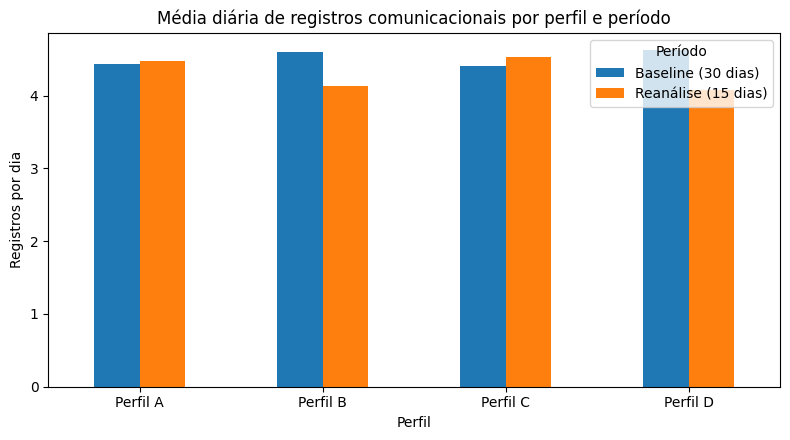

Figura salva em: C:\Users\taina.cunha\OneDrive - TELTEC SOLUTIONS LTDA\Documentos\TCC\Scripts\outputs_graficos_ajustados\fig_media_diaria_comunicacional_periodo.png

### Score comunicacional médio por perfil e período


,perfil,period_label,scoreComunicacionalMedio,evidenceCoverageMedia,diasAnalisados,sentimentoMedio,interacaoLinguisticaMedia,diversidadeLexicalMattrScore,semanticaMedia
0,Perfil A,Baseline (30 dias),67.62,1.0,30,48.007333,87.443000,100.00,71.250000
1,Perfil A,Reanálise (15 dias),66.24,1.0,15,47.424667,82.845333,95.34,73.091333
2,Perfil B,Baseline (30 dias),68.67,1.0,30,46.610667,90.659667,100.00,73.174667
3,Perfil B,Reanálise (15 dias),61.15,1.0,15,46.698000,73.326000,89.42,67.213333
4,Perfil C,Baseline (30 dias),69.20,1.0,30,47.123000,89.252000,100.00,76.455000
5,Perfil C,Reanálise (15 dias),69.45,1.0,15,45.542667,91.114000,99.70,77.386000
6,Perfil D,Baseline (30 dias),71.24,1.0,30,51.863667,89.364667,100.00,76.863000
7,Perfil D,Reanálise (15 dias),63.00,1.0,15,49.972000,72.366667,91.60,70.716000


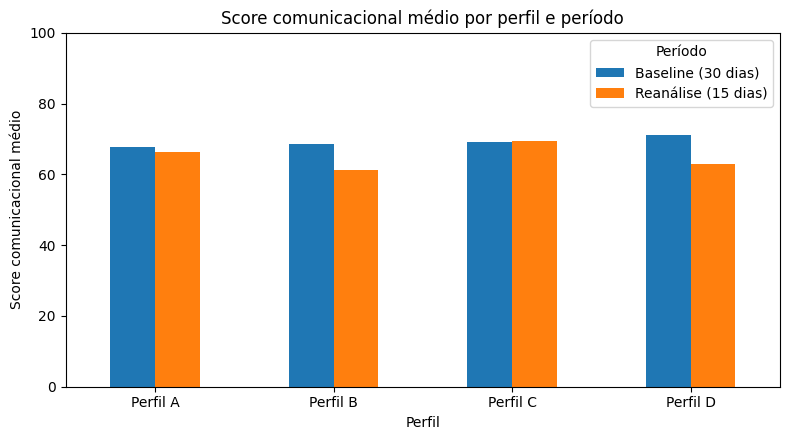

Figura salva em: C:\Users\taina.cunha\OneDrive - TELTEC SOLUTIONS LTDA\Documentos\TCC\Scripts\outputs_graficos_ajustados\fig_score_comunicacional_periodo.png

### Variação do score comunicacional: reanálise menos baseline


,perfil,baseline,reanalise,variacao
0,Perfil A,67.62,66.24,-1.38
1,Perfil B,68.67,61.15,-7.52
2,Perfil C,69.20,69.45,0.25
3,Perfil D,71.24,63.00,-8.24



### Scores profissionais por perfil e período


,perfil,period_label,scoreProfissional,evidenceCoverage,workflowProgressionScore,deadlineScore,qualityScore,workflowStageCoverageScore,deliveryScore,deadlineOnTimeScore,deadlineLateSeverityScore,reworkScore,checklistScore
0,Perfil A,Baseline (30 dias),100.0,1.0,100.0,100.00,100.0,100.0,100.0,100.00,100.00,100.0,100.0
1,Perfil B,Baseline (30 dias),100.0,1.0,100.0,100.00,100.0,100.0,100.0,100.00,100.00,100.0,100.0
2,Perfil C,Baseline (30 dias),95.1,1.0,100.0,87.74,100.0,100.0,100.0,71.43,95.83,100.0,100.0
3,Perfil D,Baseline (30 dias),100.0,1.0,100.0,100.00,100.0,100.0,100.0,100.00,100.00,100.0,100.0


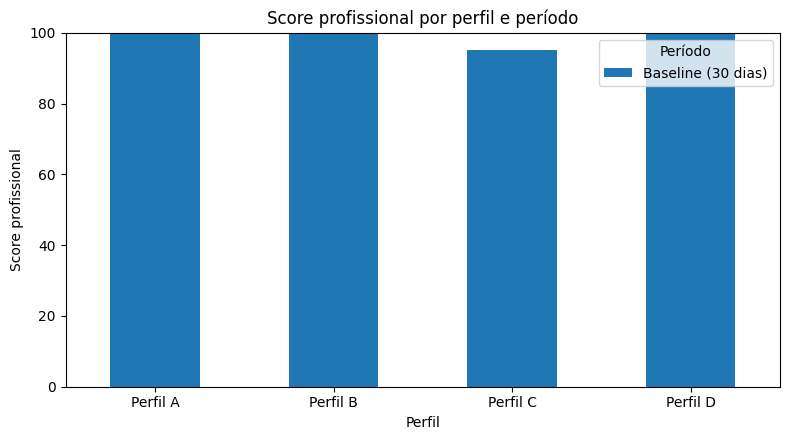

Figura salva em: C:\Users\taina.cunha\OneDrive - TELTEC SOLUTIONS LTDA\Documentos\TCC\Scripts\outputs_graficos_ajustados\fig_score_profissional_periodo.png

Arquivos exportados para: C:\Users\taina.cunha\OneDrive - TELTEC SOLUTIONS LTDA\Documentos\TCC\Scripts\outputs_graficos_ajustados


In [52]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------------------
# Configurações gerais
# --------------------------------------------------------------------------------------

BASE_DIR = Path(".")
OUTPUT_DIR = BASE_DIR / "outputs_graficos_ajustados"
OUTPUT_DIR.mkdir(exist_ok=True)

PERIOD_WINDOWS = {
    "Baseline (30 dias)": (pd.Timestamp("2026-05-01"), pd.Timestamp("2026-05-30")),
    "Reanálise (15 dias)": (pd.Timestamp("2026-05-31"), pd.Timestamp("2026-06-14")),
}

PERIOD_LABELS = {
    "baseline": "Baseline (30 dias)",
    "reanalise": "Reanálise (15 dias)"
}

USER_LABELS = {
    "user-001": "Perfil A",
    "user-002": "Perfil B",
    "user-003": "Perfil C",
    "user-004": "Perfil D",
    "member-perfil-a": "Perfil A",
    "member-perfil-b": "Perfil B",
    "member-perfil-c": "Perfil C",
    "member-perfil-d": "Perfil D",
}


def load_json(path: str | Path, default: Any = None) -> Any:
    path = Path(path)
    if not path.exists():
        return default
    with path.open("r", encoding="utf-8") as file:
        return json.load(file)


def display_df(title: str, df: pd.DataFrame, max_rows: int = 30) -> None:
    print(f"\n### {title}")
    if df.empty:
        print("Sem dados para exibir.")
        return
    try:
        display(df.head(max_rows))
    except NameError:
        print(df.head(max_rows).to_string(index=False))


def normalize_user_label(user_id: str | None) -> str | None:
    if user_id is None:
        return None
    return USER_LABELS.get(str(user_id), str(user_id))


def normalize_period(period: str | None = None, date_value: Any = None) -> str:
    if period:
        return PERIOD_LABELS.get(str(period), str(period))

    value = pd.to_datetime(date_value, errors="coerce")
    if pd.isna(value):
        return "Sem período"

    value = value.tz_localize(None) if getattr(value, "tzinfo", None) else value
    for label, (start, end) in PERIOD_WINDOWS.items():
        if start <= value <= end:
            return label

    return "Fora das janelas analisadas"


def save_current_fig(filename: str) -> None:
    path = OUTPUT_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Figura salva em: {path.resolve()}")


def flatten_scores(scores: list[dict], score_name: str) -> pd.DataFrame:
    rows = []
    for item in scores or []:
        row = {
            "userId": item.get("userId"),
            "perfil": normalize_user_label(item.get("userId")),
            "date": item.get("date"),
            "period": item.get("period"),
            score_name: item.get("score"),
            "evidenceCoverage": item.get("evidenceCoverage"),
            "warnings": "; ".join(item.get("warnings") or []),
        }
        row.update(item.get("components") or {})
        rows.append(row)
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------------------
# 1. Carregamento dos dados
# --------------------------------------------------------------------------------------

mensagens = load_json(LOG_DIR / "mensagens_simuladas_4perfis.json", [])

chat_scores = load_json(LOG_DIR / "chat_scores.json", [])

professional_period_scores = load_json(LOG_DIR / "professional_period_scores.json", [])


# --------------------------------------------------------------------------------------
# 2. Média diária da base comunicacional por perfil e período
# --------------------------------------------------------------------------------------

messages_df = pd.DataFrame(mensagens)
if not messages_df.empty:
    messages_df["createdAt"] = pd.to_datetime(messages_df["createdAt"], errors="coerce")
    messages_df["perfil"] = messages_df["userId"].map(normalize_user_label)
    messages_df["period_label"] = messages_df.apply(
        lambda row: normalize_period(row.get("period"), row.get("createdAt")),
        axis=1,
    )
    messages_df = messages_df[messages_df["period_label"].isin(PERIOD_WINDOWS)]

    volume_periodo = (
        messages_df
        .groupby(["perfil", "period_label"], dropna=False)
        .size()
        .reset_index(name="quantidade")
        .sort_values(["perfil", "period_label"])
    )
    period_days = {
        label: (end - start).days + 1
        for label, (start, end) in PERIOD_WINDOWS.items()
    }
    volume_periodo["diasPeriodo"] = volume_periodo["period_label"].map(period_days)
    volume_periodo["mediaDiariaRegistros"] = (
        volume_periodo["quantidade"] / volume_periodo["diasPeriodo"]
    ).round(2)

    display_df("Média diária de registros comunicacionais por perfil e período", volume_periodo)

    pivot = volume_periodo.pivot(
        index="perfil",
        columns="period_label",
        values="mediaDiariaRegistros",
    )
    ax = pivot.plot(kind="bar", figsize=(8, 4.5))
    ax.set_title("Média diária de registros comunicacionais por perfil e período")
    ax.set_xlabel("Perfil")
    ax.set_ylabel("Registros por dia")
    plt.xticks(rotation=0)
    plt.legend(title="Período")
    save_current_fig("fig_media_diaria_comunicacional_periodo.png")
else:
    print("Não foram encontradas mensagens para gerar o gráfico de média diária comunicacional.")


# --------------------------------------------------------------------------------------
# 3. Score comunicacional médio por perfil e período
# --------------------------------------------------------------------------------------

chat_scores_df = flatten_scores(chat_scores, "scoreComunicacional")
if not chat_scores_df.empty:
    chat_scores_df["date"] = pd.to_datetime(chat_scores_df["date"], errors="coerce")
    chat_scores_df["period_label"] = chat_scores_df["date"].apply(
        lambda value: normalize_period(date_value=value)
    )
    chat_scores_df = chat_scores_df[chat_scores_df["period_label"].isin(PERIOD_WINDOWS)]

    score_com_periodo = (
        chat_scores_df
        .groupby(["perfil", "period_label"], dropna=False)
        .agg(
            scoreComunicacionalMedio=("scoreComunicacional", "mean"),
            evidenceCoverageMedia=("evidenceCoverage", "mean"),
            diasAnalisados=("scoreComunicacional", "count"),
            sentimentoMedio=("sentimentScore", "mean"),
            interacaoLinguisticaMedia=("linguisticInteractionScore", "mean"),
            diversidadeLexicalMattrScore=("lexicalDiversityMattrPatternScore", "mean"),
            semanticaMedia=("semanticScore", "mean"),
        )
        .reset_index()
    )
    score_com_periodo["scoreComunicacionalMedio"] = score_com_periodo["scoreComunicacionalMedio"].round(2)
    score_com_periodo["evidenceCoverageMedia"] = score_com_periodo["evidenceCoverageMedia"].round(2)
    display_df("Score comunicacional médio por perfil e período", score_com_periodo)

    pivot_score_com = score_com_periodo.pivot(
        index="perfil",
        columns="period_label",
        values="scoreComunicacionalMedio",
    )
    ax = pivot_score_com.plot(kind="bar", figsize=(8, 4.5))
    ax.set_title("Score comunicacional médio por perfil e período")
    ax.set_xlabel("Perfil")
    ax.set_ylabel("Score comunicacional médio")
    ax.set_ylim(0, 100)
    plt.xticks(rotation=0)
    plt.legend(title="Período")
    save_current_fig("fig_score_comunicacional_periodo.png")

    if set(PERIOD_WINDOWS).issubset(pivot_score_com.columns):
        variacao_com = pd.DataFrame({
            "perfil": pivot_score_com.index,
            "baseline": pivot_score_com["Baseline (30 dias)"].values,
            "reanalise": pivot_score_com["Reanálise (15 dias)"].values,
        })
        variacao_com["variacao"] = (variacao_com["reanalise"] - variacao_com["baseline"]).round(2)
        display_df("Variação do score comunicacional: reanálise menos baseline", variacao_com)
else:
    print("Não foram encontrados chat_scores. Execute o cálculo dos scores comunicacionais antes desta célula.")


# --------------------------------------------------------------------------------------
# 4. Score profissional por perfil e período
# --------------------------------------------------------------------------------------
# O score NÃO é recalculado aqui. Esta célula apenas visualiza os resultados produzidos
# por calculate_professional_score(), usando os indicadores por janela exportados pelo
# notebook de extração do Trello.

professional_period_df = flatten_scores(professional_period_scores, "scoreProfissional")
if not professional_period_df.empty:
    professional_period_df["period_label"] = professional_period_df["period"].map(PERIOD_LABELS)
    professional_period_df = professional_period_df[
        professional_period_df["period_label"].isin(PERIOD_WINDOWS)
    ]

    display_cols = [
        "perfil", "period_label", "scoreProfissional", "evidenceCoverage",
        "workflowProgressionScore", "deadlineScore", "qualityScore",
        "workflowStageCoverageScore", "deliveryScore",
        "deadlineOnTimeScore", "deadlineLateSeverityScore",
        "reworkScore", "checklistScore",
    ]
    display_cols = [col for col in display_cols if col in professional_period_df.columns]
    display_df(
        "Scores profissionais por perfil e período",
        professional_period_df[display_cols].sort_values(["perfil", "period_label"]),
        max_rows=50,
    )

    pivot_score_prof = professional_period_df.pivot(
        index="perfil",
        columns="period_label",
        values="scoreProfissional",
    )
    ax = pivot_score_prof.plot(kind="bar", figsize=(8, 4.5))
    ax.set_title("Score profissional por perfil e período")
    ax.set_xlabel("Perfil")
    ax.set_ylabel("Score profissional")
    ax.set_ylim(0, 100)
    plt.xticks(rotation=0)
    plt.legend(title="Período")
    save_current_fig("fig_score_profissional_periodo.png")

    if set(PERIOD_WINDOWS).issubset(pivot_score_prof.columns):
        variacao_prof = pd.DataFrame({
            "perfil": pivot_score_prof.index,
            "baseline": pivot_score_prof["Baseline (30 dias)"].values,
            "reanalise": pivot_score_prof["Reanálise (15 dias)"].values,
        })
        variacao_prof["variacao"] = (variacao_prof["reanalise"] - variacao_prof["baseline"]).round(2)
        display_df("Variação do score profissional: reanálise menos baseline", variacao_prof)
else:
    print(
        "Não foram encontrados professional_period_scores. Execute primeiro a extração "
        "do Trello por período e depois o cálculo dos scores."
    )


# --------------------------------------------------------------------------------------
# 5. Exportação das tabelas agregadas
# --------------------------------------------------------------------------------------

if "volume_periodo" in locals() and not volume_periodo.empty:
    volume_periodo.to_csv(
        OUTPUT_DIR / "media_diaria_comunicacional_periodo.csv",
        index=False,
        encoding="utf-8",
    )
if "score_com_periodo" in locals() and not score_com_periodo.empty:
    score_com_periodo.to_csv(
        OUTPUT_DIR / "score_comunicacional_periodo.csv",
        index=False,
        encoding="utf-8",
    )
if "variacao_com" in locals():
    variacao_com.to_csv(
        OUTPUT_DIR / "variacao_score_comunicacional.csv",
        index=False,
        encoding="utf-8",
    )
if not professional_period_df.empty:
    professional_period_df.to_csv(
        OUTPUT_DIR / "scores_profissionais_periodo.csv",
        index=False,
        encoding="utf-8",
    )
if "variacao_prof" in locals():
    variacao_prof.to_csv(
        OUTPUT_DIR / "variacao_score_profissional.csv",
        index=False,
        encoding="utf-8",
    )

print(f"\nArquivos exportados para: {OUTPUT_DIR.resolve()}")
